In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import tensorflow as tf

print("TensorFlow version:", tf.__version__)
print("GPU:", tf.config.list_physical_devices('GPU'))

TensorFlow version: 2.20.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
import zipfile
import os

zip_path = "/content/drive/MyDrive/face_reactions 3.zip"
extract_path = "/content"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Unzipped successfully")
print(os.listdir("/content"))

Unzipped successfully
['.config', 'drive', '__MACOSX', 'face_reactions', 'sample_data']


In [ ]:
%cd /content/face_reactions
print(os.listdir())

/content/face_reactions
['realtime_detection.py', 'train_resnet50.py', '.ipynb_checkpoints', '.DS_Store', 'train_mobilenetv2.py', 'train_vgg16.py', 'train_model.py', 'emotion_env', 'train_efficientnetb0.py', 'dataset', 'models']


In [ ]:
import os

BASE_DIR = "/content/face_reactions"
DATASET_DIR = os.path.join(BASE_DIR, "dataset")

print("Dataset folder:", os.listdir(DATASET_DIR))

train_path = os.path.join(DATASET_DIR, "train")
test_path = os.path.join(DATASET_DIR, "test")

print("Train exists:", os.path.exists(train_path))
print("Test exists:", os.path.exists(test_path))

if os.path.exists(train_path):
    print("Train classes:", os.listdir(train_path))

if os.path.exists(test_path):
    print("Test classes:", os.listdir(test_path))

Dataset folder: ['train', '.DS_Store', 'test']
Train exists: True
Test exists: True
Train classes: ['angry', 'happy', 'disgust', '.DS_Store', 'neutral', 'sad', 'shock']
Test classes: ['angry', 'happy', 'disgust', '.DS_Store', 'neutral', 'sad', 'shock']


In [ ]:
import os
import json
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
import seaborn as sns

from tensorflow.keras.layers import (
    Input, Dense, Dropout, GlobalAveragePooling2D,
    Conv2D, MaxPooling2D, BatchNormalization, Concatenate
)
from tensorflow.keras.models import Model
from tensorflow.keras.applications import VGG16, MobileNetV2, EfficientNetB0
from tensorflow.keras.preprocessing.image import ImageDataGenerator
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.callbacks import ModelCheckpoint, EarlyStopping, ReduceLROnPlateau

from sklearn.metrics import classification_report, confusion_matrix

BASE_DIR = "/content/face_reactions"

TRAIN_DIR = os.path.join(BASE_DIR, "dataset", "train")
TEST_DIR = os.path.join(BASE_DIR, "dataset", "test")
MODEL_DIR = os.path.join(BASE_DIR, "models")

os.makedirs(MODEL_DIR, exist_ok=True)

IMG_SIZE = 224
BATCH_SIZE = 8
EPOCHS = 10

In [ ]:
train_datagen = ImageDataGenerator(
    rescale=1.0 / 255,
    rotation_range=20,
    zoom_range=0.2,
    width_shift_range=0.2,
    height_shift_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(
    rescale=1.0 / 255
)

train_generator = train_datagen.flow_from_directory(
    TRAIN_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=True
)

test_generator = test_datagen.flow_from_directory(
    TEST_DIR,
    target_size=(IMG_SIZE, IMG_SIZE),
    batch_size=BATCH_SIZE,
    class_mode="categorical",
    shuffle=False
)

NUM_CLASSES = train_generator.num_classes

print("Classes:", train_generator.class_indices)
print("Number of classes:", NUM_CLASSES)

labels_path = os.path.join(MODEL_DIR, "hybrid_labels.json")
with open(labels_path, "w") as f:
    json.dump(train_generator.class_indices, f)

print("Labels saved to:", labels_path)

Found 3776 images belonging to 6 classes.
Found 947 images belonging to 6 classes.
Classes: {'angry': 0, 'disgust': 1, 'happy': 2, 'neutral': 3, 'sad': 4, 'shock': 5}
Number of classes: 6
Labels saved to: /content/face_reactions/models/hybrid_labels.json


In [ ]:
input_layer = Input(shape=(IMG_SIZE, IMG_SIZE, 3), name="input_image")


# =========================
# VGG16 BRANCH
# =========================

vgg_base = VGG16(
    weights="imagenet",
    include_top=False,
    input_tensor=input_layer
)

for layer in vgg_base.layers:
    layer.trainable = False

vgg_features = GlobalAveragePooling2D(name="vgg16_features")(vgg_base.output)


# =========================
# MOBILENETV2 BRANCH
# =========================

mobilenet_base = MobileNetV2(
    weights="imagenet",
    include_top=False,
    input_tensor=input_layer
)

for layer in mobilenet_base.layers:
    layer.trainable = False

mobilenet_features = GlobalAveragePooling2D(name="mobilenetv2_features")(mobilenet_base.output)


# =========================
# EFFICIENTNETB0 BRANCH
# =========================

efficientnet_base = EfficientNetB0(
    weights="imagenet",
    include_top=False,
    input_tensor=input_layer
)

for layer in efficientnet_base.layers:
    layer.trainable = False

efficientnet_features = GlobalAveragePooling2D(name="efficientnetb0_features")(efficientnet_base.output)


# =========================
# CUSTOM CNN BRANCH
# =========================

x = Conv2D(32, (3, 3), activation="relu", padding="same", name="custom_conv1")(input_layer)
x = BatchNormalization(name="custom_bn1")(x)
x = MaxPooling2D((2, 2), name="custom_pool1")(x)

x = Conv2D(64, (3, 3), activation="relu", padding="same", name="custom_conv2")(x)
x = BatchNormalization(name="custom_bn2")(x)
x = MaxPooling2D((2, 2), name="custom_pool2")(x)

x = Conv2D(128, (3, 3), activation="relu", padding="same", name="custom_conv3")(x)
x = BatchNormalization(name="custom_bn3")(x)
x = MaxPooling2D((2, 2), name="custom_pool3")(x)

x = Conv2D(256, (3, 3), activation="relu", padding="same", name="custom_conv4")(x)
x = BatchNormalization(name="custom_bn4")(x)
x = MaxPooling2D((2, 2), name="custom_pool4")(x)

custom_features = GlobalAveragePooling2D(name="custom_cnn_features")(x)


# =========================
# FEATURE FUSION
# =========================

merged_features = Concatenate(name="feature_concatenation")([
    vgg_features,
    mobilenet_features,
    efficientnet_features,
    custom_features
])


# =========================
# CLASSIFICATION HEAD
# =========================

x = Dense(512, activation="relu", name="dense_512")(merged_features)
x = Dropout(0.5, name="dropout_1")(x)

x = Dense(256, activation="relu", name="dense_256")(x)
x = Dropout(0.3, name="dropout_2")(x)

output_layer = Dense(NUM_CLASSES, activation="softmax", name="emotion_output")(x)


hybrid_model = Model(
    inputs=input_layer,
    outputs=output_layer,
    name="Hybrid_VGG16_MobileNetV2_EfficientNetB0_CustomCNN"
)

hybrid_model.compile(
    optimizer=Adam(learning_rate=0.0001),
    loss="categorical_crossentropy",
    metrics=["accuracy"]
)

hybrid_model.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


/tmp/ipykernel_9167/2295920436.py:24: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  mobilenet_base = MobileNetV2(


9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "Hybrid_VGG16_MobileNetV2_EfficientNetB0_CustomCNN"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_image[0][0] │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │        864 │ stem_conv_pad[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        128 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        288 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        128 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 32)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 32)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 8)   │        264 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 32)  │        288 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 32)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        512 │ block1a_se_excit

 Total params: 23,249,897 (88.69 MB)

 Trainable params: 2,226,694 (8.49 MB)

 Non-trainable params: 21,023,203 (80.20 MB)

In [ ]:
model_path = os.path.join(MODEL_DIR, "hybrid_emotion_model.keras")

checkpoint = ModelCheckpoint(
    model_path,
    monitor="val_accuracy",
    save_best_only=True,
    mode="max",
    verbose=1
)

early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True,
    verbose=1
)

reduce_lr = ReduceLROnPlateau(
    monitor="val_loss",
    factor=0.3,
    patience=3,
    verbose=1
)

In [ ]:
history = hybrid_model.fit(
    train_generator,
    validation_data=test_generator,
    epochs=EPOCHS,
    callbacks=[checkpoint, early_stop, reduce_lr]
)

print("Hybrid model saved to:", model_path)

Epoch 1/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.2489 - loss: 1.8354
Epoch 1: val_accuracy improved from None to 0.47202, saving model to /content/face_reactions/models/hybrid_emotion_model.keras

Epoch 1: finished saving model to /content/face_reactions/models/hybrid_emotion_model.keras
472/472 ━━━━━━━━━━━━━━━━━━━━ 167s 233ms/step - accuracy: 0.2900 - loss: 1.7242 - val_accuracy: 0.4720 - val_loss: 1.4510 - learning_rate: 1.0000e-04
Epoch 2/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step - accuracy: 0.4121 - loss: 1.4749
Epoch 2: val_accuracy improved from 0.47202 to 0.56283, saving model to /content/face_reactions/models/hybrid_emotion_model.keras

Epoch 2: finished saving model to /content/face_reactions/models/hybrid_emotion_model.keras
472/472 ━━━━━━━━━━━━━━━━━━━━ 79s 166ms/step - accuracy: 0.4391 - loss: 1.4038 - val_accuracy: 0.5628 - val_loss: 1.1615 - learning_rate: 1.0000e-04
Epoch 3/10
472/472 ━━━━━━━━━━━━━━━━━━━━ 0s 134ms/step - accuracy: 0.5175 - loss: 1.2

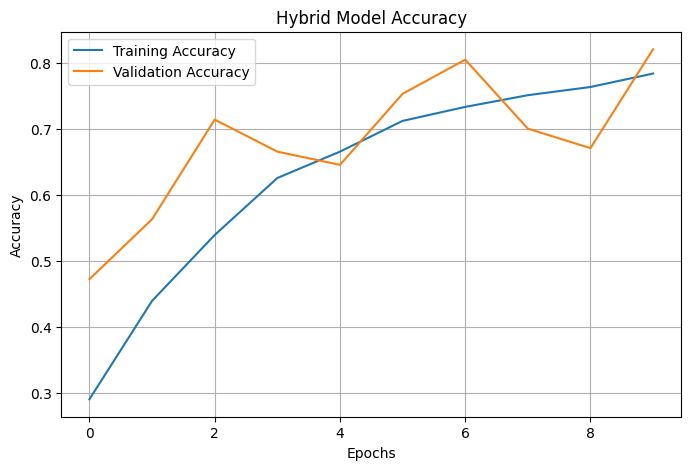

Accuracy graph saved to: /content/face_reactions/models/hybrid_accuracy.png


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")
plt.title("Hybrid Model Accuracy")
plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

accuracy_graph_path = os.path.join(MODEL_DIR, "hybrid_accuracy.png")
plt.savefig(accuracy_graph_path)
plt.show()

print("Accuracy graph saved to:", accuracy_graph_path)

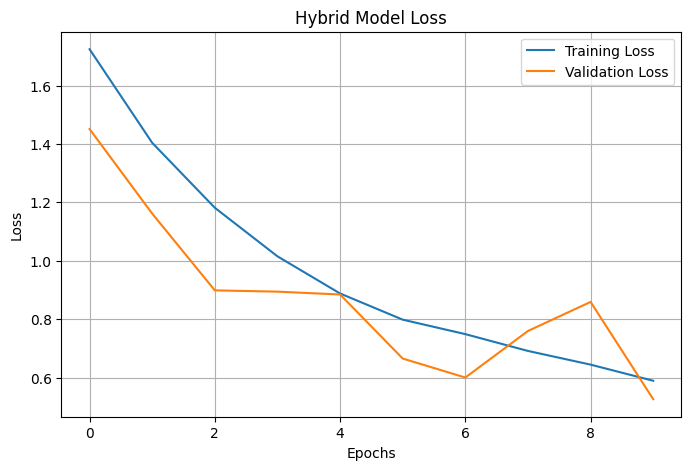

Loss graph saved to: /content/face_reactions/models/hybrid_loss.png


In [ ]:
plt.figure(figsize=(8, 5))
plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.title("Hybrid Model Loss")
plt.xlabel("Epochs")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

loss_graph_path = os.path.join(MODEL_DIR, "hybrid_loss.png")
plt.savefig(loss_graph_path)
plt.show()

print("Loss graph saved to:", loss_graph_path)

119/119 ━━━━━━━━━━━━━━━━━━━━ 41s 188ms/step


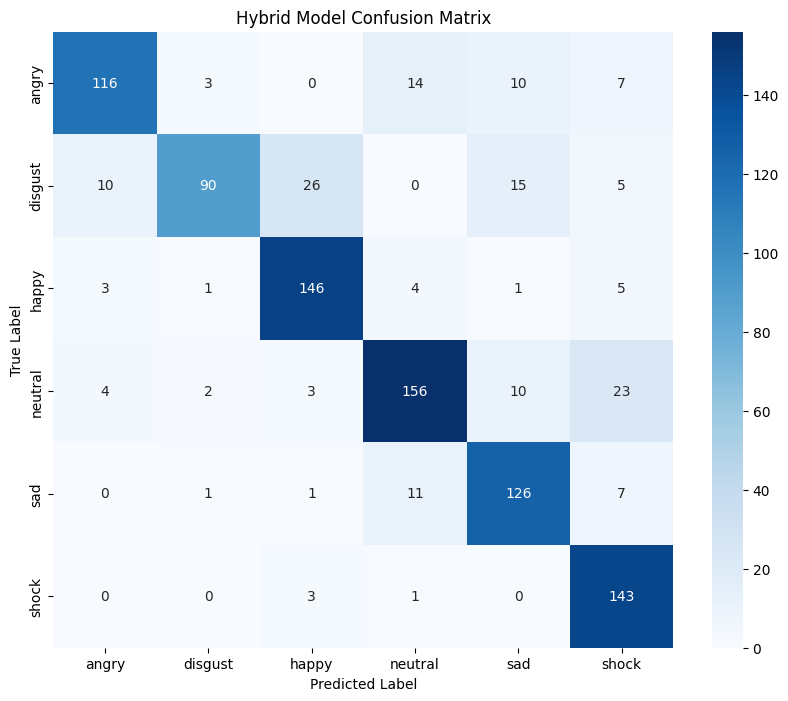

Confusion matrix saved to: /content/face_reactions/models/hybrid_confusion_matrix.png
Classification Report:
              precision    recall  f1-score   support

       angry       0.87      0.77      0.82       150
     disgust       0.93      0.62      0.74       146
       happy       0.82      0.91      0.86       160
     neutral       0.84      0.79      0.81       198
         sad       0.78      0.86      0.82       146
       shock       0.75      0.97      0.85       147

    accuracy                           0.82       947
   macro avg       0.83      0.82      0.82       947
weighted avg       0.83      0.82      0.82       947

Classification report saved to: /content/face_reactions/models/hybrid_classification_report.txt


In [ ]:
test_generator.reset()

predictions = hybrid_model.predict(test_generator)
y_pred = np.argmax(predictions, axis=1)
y_true = test_generator.classes

class_labels = list(test_generator.class_indices.keys())

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(10, 8))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_labels,
    yticklabels=class_labels
)

plt.title("Hybrid Model Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")

confusion_matrix_path = os.path.join(MODEL_DIR, "hybrid_confusion_matrix.png")
plt.savefig(confusion_matrix_path)
plt.show()

print("Confusion matrix saved to:", confusion_matrix_path)

report = classification_report(
    y_true,
    y_pred,
    target_names=class_labels
)

print("Classification Report:")
print(report)

report_path = os.path.join(MODEL_DIR, "hybrid_classification_report.txt")

with open(report_path, "w") as f:
    f.write(report)

print("Classification report saved to:", report_path)

In [ ]:
print(os.listdir(MODEL_DIR))

['vgg16_emotion_model2.keras', 'resnet50_emotion_model.keras', 'hybrid_loss.png', 'efficientnetb0_emotion_model.keras', '.DS_Store', 'hybrid_confusion_matrix.png', 'vgg16_emotion_model4.keras', 'hybrid_labels.json', 'vgg16_emotion_model.keras', 'hybrid_classification_report.txt', 'emotion_model.h5', 'hybrid_accuracy.png', 'hybrid_emotion_model.keras', 'mobilenetv2_emotion_model.keras']


In [ ]:
import shutil

shutil.make_archive(
    "/content/face_reactions_hybrid_trained",
    "zip",
    "/content/face_reactions"
)

print("Created zip:", "/content/face_reactions_hybrid_trained.zip")

Created zip: /content/face_reactions_hybrid_trained.zip


In [ ]:
shutil.copy(
    "/content/face_reactions_hybrid_trained.zip",
    "/content/drive/MyDrive/face_reactions_hybrid_trained.zip"
)

print("Copied trained project zip to Drive")

Copied trained project zip to Drive


In [ ]:
import shutil

files_to_copy = [
    "hybrid_emotion_model.keras",
    "hybrid_labels.json",
    "hybrid_accuracy.png",
    "hybrid_loss.png",
    "hybrid_confusion_matrix.png",
    "hybrid_classification_report.txt"
]

for file in files_to_copy:
    src = os.path.join(MODEL_DIR, file)
    dst = os.path.join("/content/drive/MyDrive", file)
    shutil.copy(src, dst)
    print("Copied:", file)

print("All hybrid model files copied to Google Drive")

Copied: hybrid_emotion_model.keras
Copied: hybrid_labels.json
Copied: hybrid_accuracy.png
Copied: hybrid_loss.png
Copied: hybrid_confusion_matrix.png
Copied: hybrid_classification_report.txt
All hybrid model files copied to Google Drive
